# Notebook 8 – Feature Scaling
## `08_Feature_Scaling.ipynb`

### Learning objectives
Understand why features are scaled, identify algorithms affected by feature magnitude, apply common scaling methods with scikit-learn, compare their results, and understand the effect of outliers.

**Why preprocessing is required:** Features often use different units and ranges. For example, age may range from 18–70 while annual income may range from ₹100,000–₹2,000,000. Some algorithms may give too much influence to the feature with the larger numerical range. Scaling puts features on comparable scales and helps those algorithms learn or calculate distances more fairly.

### Example context
A customer dataset contains age, annual income, and monthly website visits. We will scale the numeric features without changing the target column.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler,
    Normalizer
)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Simple example and sample data

A feature is an input column used by a model. Here, `Age`, `Annual_Income`, and `Monthly_Visits` are features. `Purchased` is the target.

**Real-world example:** An online store predicts whether a customer will purchase a product.

**Business example:** Customer age, income, and activity are measured in different units. Scaling prevents a large numeric range from dominating distance-based calculations.

**AI/ML use case:** K-nearest neighbors (KNN), support vector machines (SVM), and many gradient-based models can benefit from scaled numeric features.

In [2]:
df = pd.DataFrame({
    "Age": [22, 25, 28, 35, 42, 48, 52, 60],
    "Annual_Income": [180000, 250000, 320000, 450000, 620000, 750000, 900000, 1200000],
    "Monthly_Visits": [2, 5, 7, 10, 12, 15, 18, 22],
    "Purchased": [0, 0, 0, 1, 1, 1, 1, 1]
})
display(df)

,Age,Annual_Income,Monthly_Visits,Purchased
0,22,180000,2,0
1,25,250000,5,0
2,28,320000,7,0
3,35,450000,10,1
4,42,620000,12,1
5,48,750000,15,1
6,52,900000,18,1
7,60,1200000,22,1


## 2. Why Feature Scaling?

Scaling changes the numeric range or distribution of input features. It is useful when an algorithm compares distances, uses dot products, or optimizes coefficients using gradient-based methods.

Scaling is not a way to make data more accurate, and it does not automatically improve every model. Fit the scaler only on the training data, then use that fitted scaler to transform validation/test data. This prevents data leakage.

## 3. Scale-sensitive algorithms

Common examples that are usually sensitive to feature scale:

- K-nearest neighbors (KNN): distance calculations can be dominated by large-range features.
- K-means clustering: cluster distances depend on feature magnitudes.
- Support vector machines (especially RBF kernel): distances and margins depend on scale.
- Logistic/linear regression with regularization: penalty can be uneven across differently scaled coefficients.
- Neural networks and gradient-based optimization: scaling often improves optimization stability and speed.
- Principal component analysis (PCA): high-variance/high-scale features can dominate components.

## 4. Scale-insensitive algorithms

Tree-based models generally do not require scaling:

- Decision trees
- Random forests
- Gradient-boosted trees (for example, many implementations of XGBoost/LightGBM/CatBoost)

Trees split using thresholds within each feature, so changing a feature's scale generally does not change the ordering of its values or the resulting split structure. Scaling may still be useful for a shared preprocessing pipeline, but is not normally required for these models.

## 5. Normalization vs standardization

The words are sometimes used loosely. In this notebook:

- **Min-Max scaling** maps each feature to a selected range, usually 0 to 1.
- **Standardization** subtracts the training mean and divides by the training standard deviation. The resulting training feature has mean near 0 and standard deviation near 1.
- **Vector normalization** (`Normalizer`) scales each row to unit length. It is different from scaling each column and is often used for text vectors or direction-based comparisons.

## 6. Min-Max Scaling and `MinMaxScaler`

Min-Max scaling maps the minimum training value to 0 and maximum to 1 by default. It preserves the shape/order of values but is sensitive to extreme outliers because the minimum and maximum determine the range.

**When useful:** Features with known bounds or algorithms that work well with bounded inputs.

In [3]:
features = ["Age", "Annual_Income", "Monthly_Visits"]
X = df[features]

minmax_scaler = MinMaxScaler()
X_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X),
    columns=features
)
display(X_minmax.round(3))

,Age,Annual_Income,Monthly_Visits
0,0.000,0.000,0.000
1,0.079,0.069,0.150
2,0.158,0.137,0.250
3,0.342,0.265,0.400
4,0.526,0.431,0.500
5,0.684,0.559,0.650
6,0.789,0.706,0.800
7,1.000,1.000,1.000


## 7. Standardization and `StandardScaler`

StandardScaler uses the training mean and standard deviation. Values are expressed in standard-deviation units from the mean. It does not guarantee values between 0 and 1, and it is sensitive to outliers because mean and standard deviation are affected by extreme values.

**When useful:** Common choice for linear models, SVM, PCA, and neural networks when features are roughly well-behaved.

In [4]:
standard_scaler = StandardScaler()
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=features
)
display(X_standard.round(3))
print("Training means:", X_standard.mean().round(6).to_dict())
print("Training standard deviations:", X_standard.std(ddof=0).round(6).to_dict())

,Age,Annual_Income,Monthly_Visits
0,-1.322,-1.224,-1.483
1,-1.089,-1.012,-1.008
2,-0.856,-0.800,-0.692
3,-0.311,-0.405,-0.217
4,0.233,0.110,0.099
5,0.700,0.504,0.573
6,1.011,0.959,1.048
7,1.634,1.868,1.680


Training means: {'Age': 0.0, 'Annual_Income': 0.0, 'Monthly_Visits': 0.0}
Training standard deviations: {'Age': 1.0, 'Annual_Income': 1.0, 'Monthly_Visits': 1.0}


## 8. `RobustScaler`

RobustScaler subtracts the median and divides by the interquartile range (IQR: 75th percentile minus 25th percentile). Median and IQR are less affected by extreme values than mean and standard deviation.

**When useful:** Numeric features with genuine extreme values or strong outliers. It does not remove outliers; it reduces their influence on the scaling parameters.

In [5]:
robust_scaler = RobustScaler()
X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X),
    columns=features
)
display(X_robust.round(3))

,Age,Annual_Income,Monthly_Visits
0,-0.759,-0.732,-0.973
1,-0.621,-0.588,-0.649
2,-0.483,-0.443,-0.432
3,-0.161,-0.175,-0.108
4,0.161,0.175,0.108
5,0.437,0.443,0.432
6,0.621,0.753,0.757
7,0.989,1.371,1.189


## 9. `MaxAbsScaler`

MaxAbsScaler divides each feature by its maximum absolute value. Values are generally mapped into [-1, 1]. It does not center the data and is useful when preserving sparsity is important, such as sparse matrices.

**Limitation:** It is sensitive to extreme maximum absolute values.

In [6]:
maxabs_scaler = MaxAbsScaler()
X_maxabs = pd.DataFrame(
    maxabs_scaler.fit_transform(X),
    columns=features
)
display(X_maxabs.round(3))

,Age,Annual_Income,Monthly_Visits
0,0.367,0.150,0.091
1,0.417,0.208,0.227
2,0.467,0.267,0.318
3,0.583,0.375,0.455
4,0.700,0.517,0.545
5,0.800,0.625,0.682
6,0.867,0.750,0.818
7,1.000,1.000,1.000


## 10. Vector `Normalizer` (additional normalization method)

Normalizer works row by row, not column by column. Each sample vector is scaled to unit norm. It is useful when the direction of a vector matters more than its magnitude, such as document vectors in text classification.

Do not confuse this with MinMaxScaler.

In [7]:
row_normalizer = Normalizer()
X_row_normalized = pd.DataFrame(
    row_normalizer.fit_transform(X),
    columns=features
)
display(X_row_normalized.round(3))
print("Row L2 norms:", np.linalg.norm(X_row_normalized, axis=1).round(6))

,Age,Annual_Income,Monthly_Visits
0,0.000,1.000,0.000
1,0.000,1.000,0.000
2,0.000,1.000,0.000
3,0.000,1.000,0.000
4,0.000,1.000,0.000
5,0.000,1.000,0.000
6,0.000,1.000,0.000
7,0.000,1.000,0.000


Row L2 norms: [1. 1. 1. 1. 1. 1. 1. 1.]


## 11. Compare scaling techniques

The table compares the same feature values under each technique. There is no universally best scaler: choose based on the data distribution, outliers, algorithm, and business meaning.

In [8]:
scaled_versions = {
    "Original": X.reset_index(drop=True),
    "MinMax": X_minmax,
    "Standard": X_standard,
    "Robust": X_robust,
    "MaxAbs": X_maxabs
}
comparison = pd.concat(
    {name: frame for name, frame in scaled_versions.items()},
    axis=1
)
display(comparison.round(3))

Original                              MinMax                               \
       Age Annual_Income Monthly_Visits    Age Annual_Income Monthly_Visits   
0       22        180000              2  0.000         0.000          0.000   
1       25        250000              5  0.079         0.069          0.150   
2       28        320000              7  0.158         0.137          0.250   
3       35        450000             10  0.342         0.265          0.400   
4       42        620000             12  0.526         0.431          0.500   
5       48        750000             15  0.684         0.559          0.650   
6       52        900000             18  0.789         0.706          0.800   
7       60       1200000             22  1.000         1.000          1.000   

  Standard                              Robust                               \
       Age Annual_Income Monthly_Visits    Age Annual_Income Monthly_Visits   
0   -1.322        -1.224         -1.483 -0.759        -0.732         -0.973   
1   -1.089        -1.012         -1.008 -0.621        -0.588         -0.649   
2   -0.856        -0.800         -0.692 -0.483        -0.443         -0.432   
3   -0.311        -0.405         -0.217 -0.161        -0.175         -0.108   
4    0.233         0.110          0.099  0.161         0.175          0.108   
5    0.700         0.504          0.573  0.437         0.443          0.432   
6    1.011         0.959          1.048  0.621         0.753          0.757   
7    1.634         1.868          1.680  0.989         1.371          1.189   

  MaxAbs                               
     Age Annual_Income Monthly_Visits  
0  0.367         0.150          0.091  
1  0.417         0.208          0.227  
2  0.467         0.267          0.318  
3  0.583         0.375          0.455  
4  0.700         0.517          0.545  
5  0.800         0.625          0.682  
6  0.867         0.750          0.818  
7  1.000         1.000          1.000

In [9]:
summary = []
for name, frame in scaled_versions.items():
    for column in features:
        summary.append({
            "Method": name,
            "Feature": column,
            "Minimum": frame[column].min(),
            "Maximum": frame[column].max(),
            "Mean": frame[column].mean(),
            "Median": frame[column].median()
        })
display(pd.DataFrame(summary).round(3))

,Method,Feature,Minimum,Maximum,Mean,Median
0,Original,Age,22.000,60.000,39.000,38.500
1,Original,Annual_Income,"180,000.000","1,200,000.000","583,750.000","535,000.000"
2,Original,Monthly_Visits,2.000,22.000,11.375,11.000
3,MinMax,Age,0.000,1.000,0.447,0.434
4,MinMax,Annual_Income,0.000,1.000,0.396,0.348
5,MinMax,Monthly_Visits,0.000,1.000,0.469,0.450
6,Standard,Age,-1.322,1.634,0.000,-0.039
7,Standard,Annual_Income,-1.224,1.868,0.000,-0.148
8,Standard,Monthly_Visits,-1.483,1.680,0.000,-0.059
9,Robust,Age,-0.759,0.989,0.023,0.000


## 12. How outliers affect scaling

An outlier is a value unusually far from most observations. Consider income values with one extremely high value.

- **MinMaxScaler:** the extreme maximum stretches the range; most ordinary values may be compressed close to 0.
- **StandardScaler:** the mean and standard deviation can be pulled by the extreme value, reducing the standardized differences among ordinary observations.
- **RobustScaler:** median and IQR are more resistant, so ordinary observations usually retain a more useful spread.
- **MaxAbsScaler:** the extreme absolute maximum can make most values very small.
- **Normalizer:** each row's vector length affects how its features are scaled; it is not an outlier-robust column scaler.

Do not automatically delete a valid high-income customer. Investigate whether it is an error or a genuine observation before choosing a treatment.

In [10]:
income_with_outlier = pd.DataFrame({
    "Income": [180000, 220000, 250000, 280000, 310000, 350000, 400000, 15000000]
})
scalers = {
    "MinMax": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler(),
    "MaxAbs": MaxAbsScaler()
}
outlier_comparison = income_with_outlier.copy()
for name, scaler in scalers.items():
    outlier_comparison[name] = scaler.fit_transform(income_with_outlier[["Income"]]).ravel()
display(outlier_comparison.round(3))

,Income,MinMax,Standard,Robust,MaxAbs
0,180000,0.000,-0.399,-0.958,0.012
1,220000,0.003,-0.391,-0.625,0.015
2,250000,0.005,-0.385,-0.375,0.017
3,280000,0.007,-0.379,-0.125,0.019
4,310000,0.009,-0.373,0.125,0.021
5,350000,0.011,-0.364,0.458,0.023
6,400000,0.015,-0.354,0.875,0.027
7,15000000,1.000,2.646,122.542,1.000


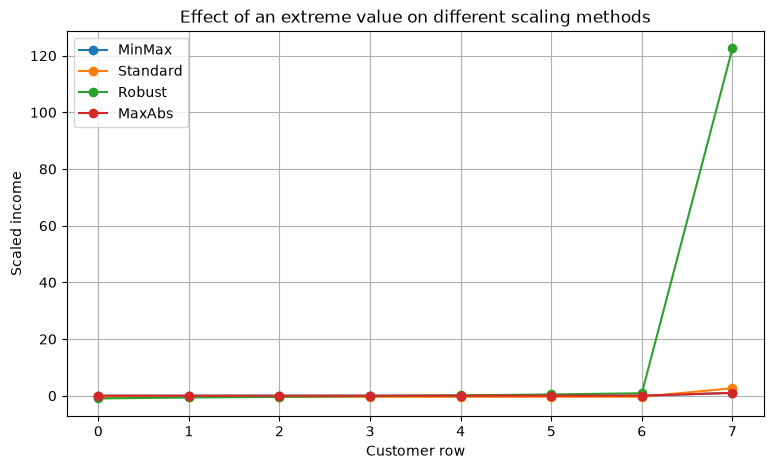

In [11]:
plt.figure(figsize=(9, 5))
for name in ["MinMax", "Standard", "Robust", "MaxAbs"]:
    plt.plot(outlier_comparison.index, outlier_comparison[name], marker="o", label=name)
plt.title("Effect of an extreme value on different scaling methods")
plt.xlabel("Customer row")
plt.ylabel("Scaled income")
plt.legend()
plt.grid(True)
plt.show()

## 13. Real-world ML example: compare a scale-sensitive and tree-based model

We use a small illustrative dataset. The pipeline fits the scaler on training rows only. KNN is distance-based and benefits from scaling. A decision tree generally does not need scaling. Accuracy on a tiny dataset is only a demonstration, not a reliable model evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df["Purchased"],
    test_size=0.25, random_state=42, stratify=df["Purchased"]
)

models = {
    "KNN without scaling": KNeighborsClassifier(n_neighbors=3),
    "KNN with StandardScaler": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
    "Decision Tree without scaling": DecisionTreeClassifier(max_depth=2, random_state=42),
    "Decision Tree with StandardScaler": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=2, random_state=42))
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({"Model": name, "Accuracy": accuracy_score(y_test, predictions)})

display(pd.DataFrame(results).sort_values("Accuracy", ascending=False))

## 14. Best practices and common mistakes

1. Split data into training and test sets before fitting a scaler.
2. Fit the scaler on training features only; transform train and test using the same fitted scaler.
3. Do not scale the target column unless the task and model require it.
4. Apply scaling only to appropriate numeric columns; categorical columns need suitable encoding.
5. Use a scikit-learn `Pipeline` during cross-validation to avoid leakage.
6. Select a scaler based on distributions, outliers, algorithm, and domain knowledge.
7. Save the fitted preprocessing pipeline with the model for consistent predictions.

### Summary

| Technique | Main operation | Outlier sensitivity | Typical use |
|---|---|---|---|
| MinMaxScaler | Maps feature range, usually 0–1 | High | Bounded inputs |
| StandardScaler | Mean 0, standard deviation 1 | High | SVM, linear models, PCA |
| RobustScaler | Median and IQR | Lower | Data with outliers |
| MaxAbsScaler | Divide by max absolute value | High | Sparse data |
| Normalizer | Unit norm per row | Not a column outlier solution | Text/vector data |

### Final takeaway
Feature scaling makes feature magnitudes more comparable for algorithms that depend on scale. It does not remove outliers or guarantee better performance for every model.